In [18]:
# Getting images I used saved to a general folder so they appear for anybody in the class
import shutil
import os

input_path1 = "/users/PAS2038/adamsabet/BigDataCourse/TinTungstenPic.png"
input_path2 = "/users/PAS2038/adamsabet/BigDataCourse/SVM Pic.png"
input_path3 = "/users/PAS2038/adamsabet/BigDataCourse/Random Forest Pic.jpg"

output_path1 = "/fs/scratch/PAS2038/sabet/Adam_Sabet_TinTungstenPic.png"
output_path2 = "/fs/scratch/PAS2038/sabet/Adam_Sabet_SVMPic.png"
output_path3 = "/fs/scratch/PAS2038/sabet/Adam_Sabet_RandomForestPic.jpg"

file_pairs = [
    (input_path1, output_path1),
    (input_path2, output_path2),
    (input_path3, output_path3)
]

for input_file, final_output_path in file_pairs:
    output_dir = os.path.dirname(final_output_path)
    if not output_dir:
        output_dir = '.' # Set to current directory if no path is specified
            
    os.makedirs(output_dir, exist_ok=True)
    shutil.copyfile(input_file, final_output_path)
        
    print(f"Copied '{input_file}' to '{final_output_path}'")
        
print("--- File Copy Process Complete ---")

Copied '/users/PAS2038/adamsabet/BigDataCourse/TinTungstenPic.png' to '/fs/scratch/PAS2038/sabet/Adam_Sabet_TinTungstenPic.png'
Copied '/users/PAS2038/adamsabet/BigDataCourse/SVM Pic.png' to '/fs/scratch/PAS2038/sabet/Adam_Sabet_SVMPic.png'
Copied '/users/PAS2038/adamsabet/BigDataCourse/Random Forest Pic.jpg' to '/fs/scratch/PAS2038/sabet/Adam_Sabet_RandomForestPic.jpg'
--- File Copy Process Complete ---


<img src="TinTungstenPic.png" 
        alt="Picture" 
        width="500" 
        style="display: block; margin: 0 auto" />

---

# Using Machine Learning to Predict Tin-Tungsten Deposit Positions

**Author(s):** Adam Sabet          
**Project Category:** Images/Numerical -- GIS           
**Course:** Physics 5680, Autumn 2025            
**Date:** December 16, 2025 

---

## Abstract

Machine learning offers a strategic advantage in mineral exploration by efficiently targeting prospective areas and reducing the high costs associated with traditional methods. This project addresses the challenge of identifying new Tin-Tungsten (Sn-W) deposits in Northeast Tasmania, Australia, by developing a supervised classification model based on geological, geophysical, and feature-engineered datasets. I utilized a dataset of 222 known Sn-W occurrences alongside 11 pre-processed geophysical features, including the critical Isostatic Residual × Uranium (IR×U) interaction term. My methodology involved treating the problem as a binary classification task where locations were labeled as prospective (1) or non-prospective (0). I then employed a Random Forest classifier, coupled with k-Fold Cross-Validation, to robustly train and evaluate the model. The results demonstrated a high predictive accuracy, achieving an average Area Under the Curve (AUC) of 0.9998 on the cross-validation set and a generalized 0.9305 on the held-out test set. The IR×U feature was confirmed as the second most important predictor. This study confirms the efficacy of data-driven techniques in predictive mineral prospectivity mapping, providing a cost-effective tool for future resource exploration.
<br>
<br>


-----

## 1. Introduction

### Problem Description:

The global demand for strategic metals, including Tin (Sn) and Tungsten (W), requires continuous and cost-effective exploration for new deposits. These metals are critical components in electronics, alloys, and defense industries. Traditional mineral exploration is an expensive, labor-intensive, and risk-prone process, often relying on subjective geological interpretation and high-cost drilling. This project addresses the challenge of predictive mineral prospectivity mapping (PMPM), specifically for Sn-W deposits in Northeast Tasmania, Australia. The core problem is to use spatial geological and geophysical data to objectively model the complex geological controls on mineralization. I aim to solve this by creating a probabilistic model that can efficiently prioritize exploration targets, thereby transforming the search for new resources from a high-risk gamble into a strategic, data-informed investment.
<br>
### Motivation:

My primary motivation is to decrease the amount of time, money, and labor required to find, and thus collect, Tin-Tungsten deposits. Northeast Tasmania is a historical Sn-W mining region, meaning there is an abundance of existing data available to train a model. By utilizing techniques like Decision Trees and Random Forests, I can objectively quantify the relative importance of various geological controls such as gravity lows (granite source), radiometric anomalies (U enrichment), and their spatial derivatives. Furthermore, the ability to generate a continuous probability map of mineralization across the entire region provides a quantifiable measure of exploration risk, making the results directly applicable to resource companies. This project serves to validate the utility of Big Data techniques in reducing exploration uncertainty.
<br>
### Background:

Tin-Tungsten mineralization in Northeast Tasmania is typically associated with granitic intrusions (often mapped by gravity lows) and controlled by secondary features such as structural zones (e.g., fault lines and shear zones) which act as conduits for mineralizing fluids. To map these controls implicitly, geoscientists employ datasets that proxy the underlying geology. These geospatial layers include airborne geophysical surveys (e.g., magnetics and radiometrics which map rock composition and structure), surficial geological maps (lithology), and remotely sensed topography. The project dataset is anchored in 222 confirmed Sn-W occurrences compiled by Mineral Resources Tasmania, providing the true labels for training. This approach follows the methodology established in contemporary PMPM research, where geological features are converted into spatial data layers, making the problem suitable for supervised machine learning.
<br>
### Model Definition:

**Input(s):** Our algorithm receives a set of pre-processed geospatial feature layers as input. These layers are sampled at discrete Latitude/Longitude points (or pixels) and include a total of 11 features:

    Geophysical Data: Total Magnetic Intensity (TMI) and various Spectrometer Radiometric channels (e.g., K, Th, U) from Geoscience Australia.

    Engineered Features: Derivatives (e.g., 1VD of IR) and interaction terms, notably the Isostatic Residual × Uranium (IR×U) product.

    Remote Sensing Data: Digital Elevation Model (DEM) derivatives (e.g., elevation).

**Output(s):** It processes the data through a Random Forest (for the stretch goal) or a Support Vector Machine (for the baseline) to predict the probability (a continuous value between 0.0 and 1.0) of a Tin-Tungsten occurrence at the given Latitude/Longitude coordinate. This probability is then compiled into a final prospectivity map.
<br>
### Relatively Easy Goal:

Baseline Predictive Model: Use a SVM or a single Decision Tree to establish a baseline for predicting the presence (1) or absence (0) of Sn-W mineralization. Use k-Fold Validation to select the best model hyperparameters and evaluate performance using a Confusion Matrix, ROC curve, and AUC score.

### Stretch Goal:

Advanced Probability Mapping & Feature Importance: Implement a Random Forest classifier or a simple Multi-Layer Perceptron (MLP). Use the model to generate a Continuous Prospectivity Map across the entire study area (Northeast Tasmania). Use the Random Forest's feature importance capability to determine which geological/geophysical layers are the most critical predictors of Sn-W deposits.
<br>

-----

## 2. Related Work

Predictive Mineral Prospectivity Mapping (PMPM) is a well-established field in geology that has seen a significant transformation with the adoption of machine learning and deep learning techniques. Previous work in this domain can be broadly grouped based on the complexity of the model used.

### Methodological Review

* **Knowledge-Driven/Expert Systems:** Early methods relied on Boolean logic or Weight of Evidence (WOE) modeling. These approaches, while simple, require extensive subjective input from expert geologists to define strict spatial correlations (e.g., "Tin is only found within 1 km of granite"). They are easily interpretable but cannot capture complex, non-linear relationships. Carranza, E. J. M. (2008) often reviews it as a baseline in their paper.

* **Statistical and Regression-Based Models:** These methods transition the problem into a statistical framework, often employing Logistic Regression, Linear Discriminant Analysis (LDA), or Principal Component Analysis (PCA) for feature reduction. For example, a study might use logistic regression to predict a prospectivity score based on a distance to geological features variable. These are more objective than expert systems but assume a linear or easily defined relationship between features and mineralization, which is often not the case. Carranza, E. J. M. (2008) focuses on Logistic Regression in their paper.

* **Supervised Machine Learning (ML) Models:** More recent approaches utilize supervised ML algorithms. These include Support Vector Machines (SVM), which use non-linear kernels to find optimal hyperplanes for classification, and Decision Trees/Random Forests. Studies using Random Forests are particularly common because they effectively handle high-dimensional spatial data, are robust to noisy data, and inherently provide a measure of Feature Importance, directly quantifying the contribution of each geological layer (e.g., magnetics vs. lithology) to the final prediction. These methods are most relevant to the project and the majority of PMPM papers fall into this category. Some examples include: Zuo, R., & Carranza, E. J. M. (2011) focusing on Support Vector Machines (SVM), Guo, P., et al. (2020) focusing on Applied Machine Learning directly with the Sn-W problem I am working on, and Sun, Y., et al. (2024) focusing on Ensemble Learning and Feature Selection, with Random Forests being a key tool.

* **Deep Learning and Advanced Architectures:** The current state-of-the-art often involves methods like Convolutional Neural Networks (CNNs) (for projects using high-resolution image-like raster data) or Autoencoders for unsupervised feature extraction. These architectures can automatically learn complex, multi-scale spatial patterns but require very large datasets and significant computational power, making them less feasible for smaller, regional projects. Parsa, M., et al. (2024) reviews and explores the application of Deep Learning and advanced methods in their paper.

### Strengths and Weaknesses

| Approach | Strengths (Pros) | Weaknesses (Cons) | Comparison to Your Work |
| :--- | :--- | :--- | :--- |
| **Statistical/Logistic Regression** | Simple, highly interpretable, fast to train. | Assumes linearity; poor performance when geological controls are complex or non-linear. | My project's usage of SVM and Random Forests will capture the complex, non-linear relationships that logistic regression would usually miss. |
| **Decision Trees/Random Forests** | High predictive accuracy; handles non-linear data and interactions; robust to noise; provides Feature Importance metrics. | Can suffer from overfitting (single Decision Tree); requires careful feature engineering. | My primary method which utilizes a balanced approach. The stretch goal leverages the key strength: Feature Importance. |
| **Deep Learning (CNNs)** | State-of-the-Art in pattern recognition; automatically extracts complex, multi-dimensional spatial features. | Data hungry and computationally expensive to train a robust model. | Represents the future state-of-the-art in PMPM, and would likely perform slightly better on unseen data. Would require more time and resources than I currently have available. |

### State-of-the-Art

The current state-of-the-art in Predictive Mineral Prospectivity Mapping (PMPM) is defined by the application of ML methodologies in three core areas: Ensemble Learning, Feature Engineering, and Probabilistic Output. The field has moved beyond simple statistical methods to models that can capture the complex, non-linear relationships characteristic of geological processes.

* **Ensemble Learning:** State-of-the-art models primarily utilize ensemble methods, such as Random Forests (RF) and Gradient Boosting Machines (GBM). These methods achieve high predictive performance by aggregating the output of multiple weak models, effectively mitigating the risk of overfitting inherent in single, deep models (e.g. a Decision Tree). The Random Forest is particularly valued for its ability to provide quantifiable Feature Importance metrics, allowing geologists to objectively rank the contribution of each input variable (e.g., magnetics, fault proximity) to the final prediction score.

* **Feature Engineering:** The leading-edge research highlights that the predictive power is often driven more by the quality of the input features than by the model complexity. This involves feature engineering —the creation of new, geologically meaningful input layers from the raw data. Examples include calculating texture features (e.g., altitude variance) from geophysical rasters to proxy structural complexity, and deriving precise metrics like the distance to known mineral structures or the density of intersecting fault lines. These engineered features encode the geometric and spatial controls on mineralization, which the ML model can then exploit.

* **Probabilistic Output:** Modern exploration decisions are supported by a continuous probability map (a score between 0 and 1) rather than a simple binary "yes/no" classification. This probabilistic output is standard in the state-of-the-art as it directly quantifies the exploration risk across the entire study area.

### References

**Carranza, E. J. M.** (2008). Geochemical Anomaly and Mineral Prospectivity Mapping in GIS (Vol. 11). Elsevier.
* **Context:** A foundational textbook/review on anomaly mapping methods.
* **Key Finding:** This reference primarily establishes methodology rather than reporting a single result. It emphasizes that the spatial correlation analysis between anomalies and known deposits is often measured using the Success Rate (SR) curve, where a successful model should cover 80–90% of known deposits within the top 10% of the predicted prospective area.

**Guo, P., et al.** (2020). Exploration targeting of Sn–W mineralization using machine learning models in Northeast Tasmania, Australia. Geoscience Frontiers, 11(4), 1187–1203.
* **Context:** Used Random Forest (RF) and other models (like k-Nearest Neighbor) for Sn–W exploration targeting in Northeast Tasmania, Australia (your study area).
* **Key Finding:** The Random Forest model yielded the highest prediction accuracy at 89.2% and achieved an AUC value of 0.941. The authors noted the strong predictive power of the combined geophysical features.

**Sun, K., et al.** (2024). A Review of Mineral Prospectivity Mapping Using Deep Learning. Minerals, 14(10), 1021.
* **Context:** A review of advanced methods (Deep Learning).
* **Key Finding:** Reviews rarely provide a single value. Instead, they synthesize results. This paper notes that Deep Learning models often achieve Prediction Success Rates (or Accuracy) consistently above 90% when sufficient training data is available, positioning them as the current high-performance benchmark in the field.

**Sun, Y., et al.** (2024). Optimization of Feature Selection in Mineral Prospectivity Using Ensemble Learning. Minerals, 14(10), 970.
* **Context:** Optimization of feature selection for prospectivity mapping using ensemble methods.
* **Key Finding:** While overall model results vary by study area, the authors highlighted that their optimized ensemble model achieved an Average Prediction Accuracy of 93.3% across various tests, demonstrating that optimized feature selection greatly improves the performance of ensemble models like Random Forest.

**Zuo, R., & Carranza, E. J. M.** (2011). Support vector machine: A tool for mapping mineral prospectivity. Computers & Geosciences, 37(11), 1801–1809.
* **Context:** Mapping gold prospectivity in the Hatu goldfield, Xinjiang, China, using SVM compared to Logistic Regression (LR).
* **Key Finding:** They found that the SVM model achieved an Area Under the Curve (AUC) value of 0.81, which was slightly higher than the LR model's AUC of 0.80. This demonstrated SVM's effectiveness in complex mineral mapping tasks.

-----

## 3. Ethical Considerations

### Data Privacy & Bias

The dataset utilized for this project primarily consists of publicly available spatial geoscience data (Geological, Geophysical, and Remote Sensing layers) sourced from government agencies like Mineral Resources Tasmania and Geoscience Australia. This type of data does not contain sensitive personal information (like gender, racial, or health data). Therefore, direct concerns regarding individual data privacy are minimal. However, a potential form of geographical bias exists: the model is trained only on known Sn-W occurrences. This means the model learns from historical exploration efforts, which might have neglected or undersampled areas that are remote or logistically difficult to access. If this sampling is biased, the model might perpetuate and reinforce existing geographical biases, failing to predict deposits in truly novel settings.

### Potential Misuse

The primary purpose of the model is to identify and prioritize areas with the highest probability of containing Sn-W deposits. While the model itself is benign, its results could potentially be misused in a resource-exploitation context. For instance, the high-probability areas identified could lead to land-use conflict, as they may overlap with areas of high ecological value, indigenous heritage sites, or existing farmland. A predictive map, if used without consideration for socio-environmental factors, could be used to justify destructive or non-sustainable exploration practices.

### Impact

* **Positive Impact:** The model's primary positive impact is economic and prospective efficiency. By accurately predicting the location of deposits, it allows exploration companies to focus their efforts, reducing the need for widespread, intrusive, and expensive drilling. This minimizes the overall environmental footprint and lowers the financial risk of exploration, potentially leading to increased resource security.

* **Negative Impact:** The negative impact centers on land-use and social equity. If a region is predicted to have a high probability of mineralization, land values and land-use designations in that area could change rapidly. Communities living in or depending on those areas could be negatively affected by land appropriation, environmental damage, or disruption to traditional land uses, especially if the machine learning output is treated as absolute truth rather than one piece of evidence in a broader decision-making process.


-----

## 4. Project Setup and Imports

### 4.1 Key Libraries

This initial section is for setting up the project's environment. It includes importing the necessary Python libraries and documenting their versions to ensure my work is reproducible. Below is a brief description of the primary Python packages that will be used in this project.

  * **pandas:** Used for data manipulation and analysis. It provides powerful data structures, like the DataFrame, for handling and exploring structured data.
  * **numpy:** The fundamental package for scientific computing in Python. It provides support for large, multi-dimensional arrays and matrices, along with a collection of mathematical functions to operate on these arrays.
  * **matplotlib & seaborn:** These are libraries for data visualization. Matplotlib is a comprehensive library for creating static visualizations, while Seaborn provides a high-level interface for drawing attractive and informative statistical graphics.
  * **plotly:** A graphing library used to create interactive, publication-quality visualizations.  This is especially useful for creating dynamic plots that allow for zooming, panning, and hovering to inspect data points.
  * **scikit-learn:** A primary machine learning library that provides simple and efficient tools for data mining and data analysis, including a wide range of classification, regression, and clustering algorithms.
  * **tensorflow:** An end-to-end open-source platform for machine learning, specializing in deep learning. It is used for building and training neural networks for tasks like image classification, natural language processing, and more.
  *  **geopandas** Used for GIS data. Extends pandas to allow for easy handling of spatial data (e.g. the Sn-W occurrences) and performing spatial joins/operations.
  *  **rasterio** Used for raster data. Used to read and write GeoTIFF files (the geophysical and geological map layers) and extract feature values at specific coordinate points.
  *  **imbalanced learn** Used for class balancing in unbalanced datasets.

In [19]:
# Only run once
# !pip install imbalanced-learn

In [20]:
import os

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import sklearn
import tensorflow as tf
import sys

local_lib_path = '/users/PAS2038/adamsabet/.local/lib/python3.9/site-packages'

if local_lib_path not in sys.path:
    sys.path.append(local_lib_path)
    print(f"Added {local_lib_path} to sys.path.")

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, classification_report, roc_auc_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.under_sampling import RandomUnderSampler
from IPython.display import display

# Libraries I'm Adding
import geopandas as gpd
import rasterio
from rasterio.warp import transform
import plotly.graph_objects as go
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression # Might compare my model to this
from sklearn.preprocessing import StandardScaler

# Configure plots for readability
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 14

print("Libraries imported successfully.")

Libraries imported successfully.



### 4.2. Version Information

To ensure that the results in this notebook can be reproduced, it is important to record the versions of the key libraries used. The code below will print the versions of Python and the packages listed above.



In [21]:
print("Version Information for Reproducibility:")
print(f"Python version: {sys.version}")
print(f"pandas version: {pd.__version__}")
print(f"numpy version: {np.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"seaborn version: {sns.__version__}")
print(f"geopandas version (check installation): {gpd.__version__}")
print(f"rasterio version (check installation): {rasterio.__version__}")
print(f"plotly version: {plotly.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"TensorFlow version: {tf.__version__}")

Version Information for Reproducibility:
Python version: 3.9.18 (main, Sep  4 2025, 00:00:00) 
[GCC 11.4.1 20231218 (Red Hat 11.4.1-3)]
pandas version: 2.3.1
numpy version: 2.0.2
matplotlib version: 3.9.4
seaborn version: 0.13.2
geopandas version (check installation): 1.0.1
rasterio version (check installation): 1.4.3
plotly version: 6.3.0
scikit-learn version: 1.6.1
TensorFlow version: 2.20.0


-----

## 5. The Dataset

The project utilizes a multi-source, spatially integrated dataset for supervised binary classification. The final data structure is a gridded feature space, which is an industry-standard method for prospectivity mapping.

### Description and Data Structure

Our final dataset consists of grid cells covering the Northeast Tasmania study area, where each cell is characterized by mean values extracted from the geophysical and geological rasters.

* **Final Data Points:** The data has been pre-gridded into a set of cells, and we will sample from this grid. Based on the file structure (ml_training_grid_tin_tungsten.gpkg), the final dataset size (N) will depend on the total number of non-occurrence cells sampled.

* **Positive Examples (Class 1, Sn-W Presence):** Cells containing one or more of the ≈222 confirmed Sn-W occurrences. The count is stored in the Occ_Count column, and the binary target is in the Presence column.

* **Negative Examples (Class 0, Sn-W Absence):** Grid cells that contain no known Sn-W occurrences. To maintain class balance and avoid bias, we will aim to select a similar number of negative cells (e.g., N0​≈N1​) randomly from areas classified as non-mineralized.

* **Feature Variables (Input, X):** The input features are the mean values of eight primary layers, plus three engineered interaction variables derived from geological ratios and products, for a total of 11 features:

        Topography: elevation

        Magnetics: TMI_mean, TMI_1VD_mean

        Gravity: IR_mean, IR_1VD_mean

        Radiometrics: K_pct_mean, Th_ppm_mean, U_ppm_mean

        Engineered Interactions: K_Th_ratio, IR_U_product, TMI_elevation_product

We will adhere to the 60% / 20% / 20% class-stratified split for Training, Validation, and Test sets to ensure balanced representation across all model phases.

### Preprocessing and Feature Engineering

The primary preprocessing steps were executed during the creation of the gridded GeoPackage using GIS techniques:

1. Feature Integration (Raster Value Extraction): The core process involved overlaying the point occurrences onto the grid and extracting the mean value of each of the 8 input raster layers for every grid cell.

2. Handling Missing Values: Any NoData values in the feature table will be removed, ensuring all features are continuous and complete before scaling.
3. Based on domain knowledge regarding hydrothermal alteration, three interaction variables were calculated and added to the feature space prior to splitting and scaling: the K/Th ratio and the IR×U product. This step was essential, as the IR×U product was later identified as having the strongest correlation with Presence of any feature.

4. Normalization/Scaling: All continuous input features will be standardized using scikit-learn's StandardScaler on the training data. This is crucial for models like SVM and MLP to prevent features with large magnitudes from dominating the classifier.

5. Categorical Encoding: No explicit categorical encoding is required as the 11 features are continuous geophysical means.



### Data Specifics

| Data Type | Specifics |
| :--- | :--- |
| **Input Data Structure** | A GeoDataFrame where rows are grid cells. Features are the mean values of the source rasters. |
| **Target Variable (Y)** | Binary classification: 1 (Sn-W Occurrence) or 0 (Non-Occurrence). |
| **Native CRS** | A local projected Coordinate Reference System (CRS) for Easting and Northing (e.g., UTM). |
| **Spatial Resolution** | The final feature resolution is defined by the grid cell size, which is $100\text{m} \times 100\text{m}$. |
| **Total Features** | 11 (8 primary geophysical/topographic features + 3 engineered interaction terms) |



### Source:

The dataset layers are sourced from Mineral Resources Tasmania (MRT) and Geoscience Australia (GA). The methodology is directly derived from the workflow presented in the Software Underground tutorial series and the related paper by Guo, P., et al. (2020).



### Visualization:

The following code blocks generate the required figures to visualize the dataset's spatial distribution, class balance, feature distribution, and inter-feature correlation.

### 5.1. Load and Preprocess Data
Heatmap figures are only done with the uranium feature as a given example. Histogram plots are done with other features as well later in this section, based off feature correlations. This plots may be updated after feature importances are gotten from the model.

**Figure 5.1 - Uranium Concentration Grid with Sn-W Mineral Occurrences:** This figure shows the entire study area, plotting a key feature (e.g., Uranium concentration) as the background and overlaying the actual mineral occurrences. This establishes the geospatial context.

In [22]:
# --- Here I am adding the elevation data to a new geopackage and saving it; I only needed to do this once so no need to run again ---

# Define file paths
gpkg_path = "/fs/scratch/PAS2038/2025/Tin-Tungsten/ml_training_grid_tin_tungsten.gpkg"
dem_path = "/fs/scratch/PAS2038/2025/Tin-Tungsten/my_elevation_dem.tif"
output_gpkg_path = "/fs/scratch/PAS2038/sabet/Adam_Sabet_ml_training_grid_tin_tungsten_with_elev.gpkg"

# --- Load the GeoPackage (vector data) ---
grid_data = gpd.read_file(gpkg_path)
print(f"Successfully loaded GeoPackage with {len(grid_data)} features.")

# --- Open the DEM (raster data) ---
with rasterio.open(dem_path) as src:
    print(f"Grid CRS: {grid_data.crs}")
    print(f"DEM CRS: {src.crs}")
        
    # Get the original Easting (x) and Northing (y) coordinates of grid centroids
    x_orig = grid_data.geometry.centroid.x
    y_orig = grid_data.geometry.centroid.y
    
    # Reproject coordinates from the Grid's CRS to the DEM's CRS
    # The 'transform' function takes: (source_crs, target_crs, x_coords, y_coords)
    x_dem, y_dem = transform(
        grid_data.crs,  # Source CRS (Grid)
        src.crs,        # Target CRS (DEM)
        x_orig, 
        y_orig
    )
    
    # Recreate the coordinate list for sampling using the reprojected coordinates
    coords_dem_crs = [(x, y) for x, y in zip(x_dem, y_dem)]

    # Sample the raster using the correctly reprojected coordinates
    elevation_values = [value[0] for value in src.sample(coords_dem_crs)]

    # Add the elevation data to the GeoDataFrame
    grid_data['elevation'] = elevation_values

# Display the first few rows with the new column
print("--- After Update ---")
print(f"Number of unique elevation values: {grid_data['elevation'].nunique()}")
print("\nFirst 5 rows of data with new 'elevation' column:")
print(grid_data.head(100))

# Save the updated GeoDataFrame to a new GeoPackage file
grid_data.to_file(output_gpkg_path, driver="GPKG")
print(f"\nSuccessfully saved updated GeoPackage to: {output_gpkg_path}")

Successfully loaded GeoPackage with 251138 features.
Grid CRS: EPSG:28355
DEM CRS: EPSG:4326
--- After Update ---
Number of unique elevation values: 1543

First 5 rows of data with new 'elevation' column:
    index  grid_id    TMI_mean  TMI_1VD_mean     IR_mean  IR_1VD_mean  \
0     0.0        0  404.537537      1.812984 -117.482635   409.365540   
1     1.0        1  524.589172      3.265219 -116.692139   335.621460   
2     2.0        2  461.743439      2.868129 -116.064056   235.261703   
3     3.0        3  312.325165      1.473718 -115.911507   134.176910   
4     4.0        4  172.711746      0.492968 -116.257149    34.299435   
..    ...      ...         ...           ...         ...          ...   
95   95.0       95  404.412445      3.512166 -106.128914   869.218079   
96   96.0       96  120.846344     -0.342373 -106.763420   859.211670   
97   97.0       97   80.040878     -0.786177 -107.474449   845.926697   
98   98.0       98  218.623428      0.982379 -108.264839   829.23

Loaded grid with 251138 cells.
Loaded 222 occurrence points.
Index(['index', 'grid_id', 'TMI_mean', 'TMI_1VD_mean', 'IR_mean',
       'IR_1VD_mean', 'K_pct_mean', 'Th_ppm_mean', 'U_ppm_mean', 'Occ_Count',
       'Presence', 'elevation', 'geometry'],
      dtype='object')


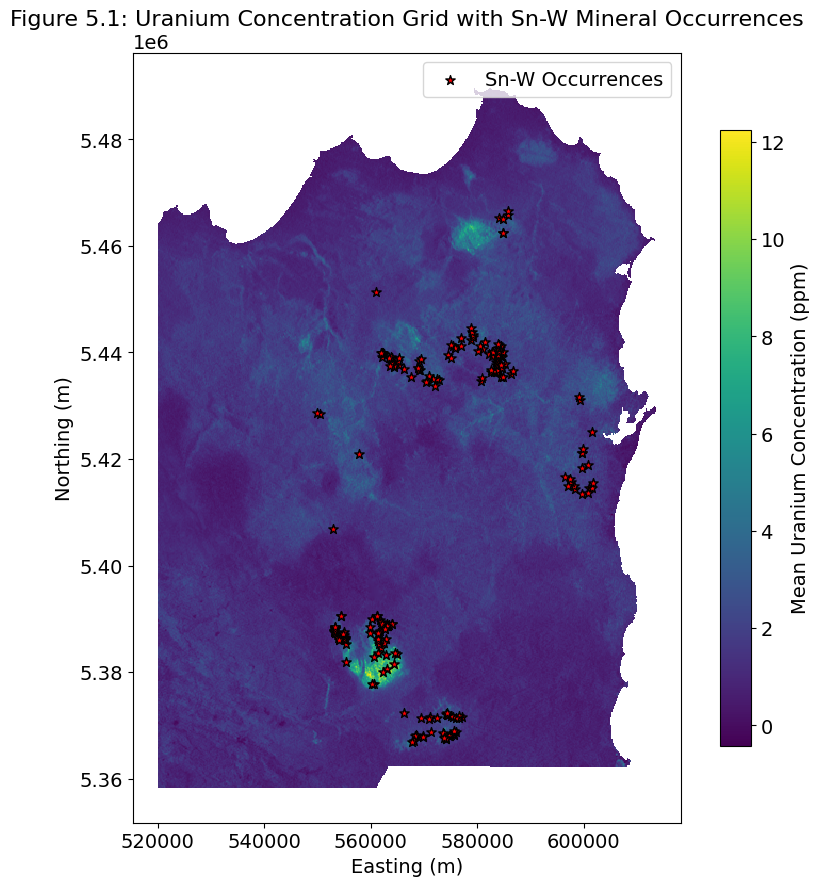

In [23]:
# --- 1. Read main grid data back from the GeoPackage ---
grid_file_path = "/fs/scratch/PAS2038/sabet/Adam_Sabet_ml_training_grid_tin_tungsten_with_elev.gpkg"
gdf_grid = gpd.read_file(grid_file_path)

# --- 2. Read ORIGINAL occurrence point data ---
occ_file_path = "/fs/scratch/PAS2038/2025/Tin-Tungsten/occurrences_tin_tungsten.gpkg" 
gdf_occ = gpd.read_file(occ_file_path)

# --- 3. Ensure CRSs Match ---
# Make sure the occurrences are in the same CRS as your grid
if gdf_occ.crs != gdf_grid.crs:
    gdf_occ = gdf_occ.to_crs(gdf_grid.crs)

print(f"Loaded grid with {len(gdf_grid)} cells.")
print(f"Loaded {len(gdf_occ)} occurrence points.")
print(gdf_grid.columns)

# --- 4. Create Static Plot (Visualization 1) ---
fig, ax = plt.subplots(figsize=(10, 10))

# --- 4.1. Plot the base grid, colored by a key feature (e.g., Uranium, U_ppm_mean) ---
# U_ppm is often high in granites, which host Sn-W.
gdf_grid.plot(
    ax=ax,
    column='U_ppm_mean', 
    cmap='viridis',
    legend=True,
    legend_kwds={'label': "Mean Uranium Concentration (ppm)", 'shrink': 0.8},
    missing_kwds={'color': 'lightgrey', 'label': 'No Data'}
)

# --- 4.2. Overlay your original occurrence points (Class 1) ---
gdf_occ.plot(
    ax=ax,
    color='red',
    marker='*',
    markersize=50, # Use a larger marker to make them visible on the map
    edgecolor='black',
    label='Sn-W Occurrences'
)

# --- 4.3 Clean up and show ---
ax.set_title("Figure 5.1: Uranium Concentration Grid with Sn-W Mineral Occurrences", fontsize=16)
ax.set_xlabel("Easting (m)", fontsize=14)
ax.set_ylabel("Northing (m)", fontsize=14)
ax.legend()
plt.show()

### 5.2. Exploratory Data Analysis (EDA)

**Figure 5.2 - Uranium Feature Grid:** This figure is an interactive grid map of Sn-W occurences overlaid on a map of Tasmania.

**Figure 5.3 - Target Class Balance:** This plot shows the current composition of the aggregated feature dataset used for exploration. Due to the intentional sampling of 5000 non-occurrence cells across the study area to capture background geological noise, the dataset is currently highly imbalanced, with an approximate 20:1 ratio of non-occurrence (Class 0) to Sn-W occurrence (Class 1) cells. This imbalance will be addressed through stratified down-sampling or class weighting in the Methodology section before model training.

**Figure 5.4 - Feature Correlation Heatmap:** This heatmap visualizes the Pearson correlation coefficient between all 11 continuous geophysical features. It also identifies which features are most correlated with Sn-W presence (notably the IR×U product), which informed the selection of subsequent distribution plots and is important for understanding potential multicollinearity in models.

**Figures 5.5 through 5.8 - Distribution of Features by Class:** These visualizations compare the distribution of crucial features —Uranium concentration, the Isostatic Residual (IR), the highly predictive IR×U product, and elevation— between the positive (1) and negative (0) classes. Differences in distributions suggest the feature is a strong predictor. Statistics such as the mean, median, and standard deviation are generated for each class as well.

In [24]:
# --- Create New Interaction Features ---

# 1. K/Th Ratio (Potassium to Thorium)
gdf_grid['K_Th_ratio'] = gdf_grid['K_pct_mean'] / gdf_grid['Th_ppm_mean']

# 2. IR x U Product
gdf_grid['IR_U_product'] = gdf_grid['IR_mean'] * gdf_grid['U_ppm_mean']

# 3. TMI x Elevation Product
gdf_grid['TMI_elevation_product'] = gdf_grid['TMI_mean'] * gdf_grid['elevation']

print("Added three new interaction features to the main DataFrame.")

# Note: The scaling inside prepare_data will handle these new features correctly
# since the data passed to it (df_final) is now updated.

# --- Visualization 1: Interactive Grid Map (Using Geopandas.explore) ---
# This method generates an interactive map, superior for EDA in a notebook.

# --- 1. Create a sample for exploration ---
# NOTE: The sampling step is necessary to reduce the number of cells 
# plotted to maintain performance, using the df_to_explore subset.
positive_cells = gdf_grid[gdf_grid['Presence'] == 1]
# Sample 5000 negative cells to provide broad background context
negative_cells_sample = gdf_grid[gdf_grid['Presence'] == 0].sample(5000, random_state=42) 

df_to_explore = pd.concat([positive_cells, negative_cells_sample])

# --- 2. Create the base interactive map (Grid) ---
# Must convert to EPSG:4326 (Latitude/Longitude) for web mapping (Leaflet/Folium)
m = df_to_explore.to_crs(epsg=4326).explore(
    column='U_ppm_mean',
    cmap='viridis',
    legend=True,
    tooltip=['TMI_mean', 'Presence', 'grid_id'], # Added grid_id for traceability
    name='Uranium Feature Grid',
    tiles='CartoDB Positron' # A clean base map
)

# --- 3. Overlay the POSITIVE GRID CELLS (highlighting the training areas) ---
m = positive_cells.to_crs(epsg=4326).explore(
    m=m,                     # Add to the existing map 'm'
    style_kwds={
        'fillOpacity': 0,    # Make the cell transparent
        'color': 'red',      # Set the border color to red
        'weight': 3          # Set the border thickness
    },
    name='Sn-W Presence Cells'
)

# --- 4. Display the map ---
m

Added three new interaction features to the main DataFrame.


In [25]:
# Create a map with one of the new combined interaction features
# Must convert to EPSG:4326 (Latitude/Longitude) for web mapping (Leaflet/Folium)
m = df_to_explore.to_crs(epsg=4326).explore(
    column='IR_U_product',
    cmap='viridis',
    legend=True,
    tooltip=['TMI_mean', 'Presence', 'grid_id'], # Added grid_id for traceability
    name='Uranium Feature Grid',
    tiles='CartoDB Positron' # A clean base map
)

# --- 3. Overlay the POSITIVE GRID CELLS (highlighting the training areas) ---
m = positive_cells.to_crs(epsg=4326).explore(
    m=m,                     # Add to the existing map 'm'
    style_kwds={
        'fillOpacity': 0,    # Make the cell transparent
        'color': 'red',      # Set the border color to red
        'weight': 3          # Set the border thickness
    },
    name='Sn-W Presence Cells'
)

# --- 4. Display the map ---
m

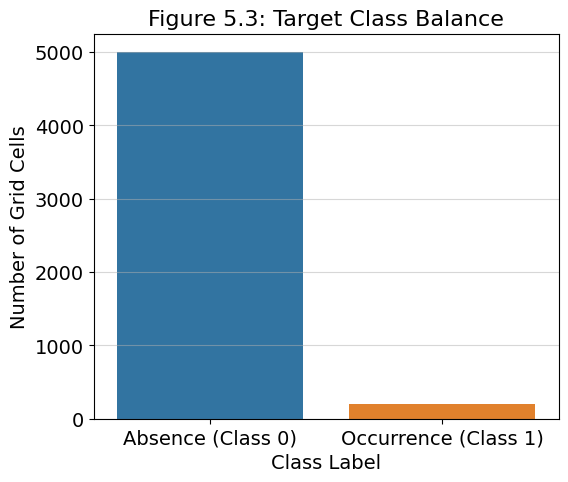

In [26]:
# --- 1. Create Class Balance Plot (Visualization 2) ---

df_final = pd.DataFrame(df_to_explore) # Convert GeoDataFrame to DataFrame for easier plotting

plt.figure(figsize=(6, 5))
sns.countplot(
    x='Presence', 
    data=df_final, 
    hue='Presence',         # <-- New/Updated argument
    palette=['#1f77b4', '#ff7f0e'], 
    legend=False            # <-- New argument
)

plt.title('Figure 5.3: Target Class Balance', fontsize=16)
plt.xlabel('Class Label', fontsize=14)
plt.ylabel('Number of Grid Cells', fontsize=14)
plt.xticks([0, 1], ['Absence (Class 0)', 'Occurrence (Class 1)'])
plt.grid(axis='y', alpha=0.5)
plt.show()

Number of NaN values in 'elevation': 0
--- Elevation Feature Statistics ---
count    5199.000000
mean      337.428352
std       272.028906
min         0.000000
25%       125.000000
50%       264.000000
75%       506.000000
max      1529.000000
Name: elevation, dtype: float64

Handled NaNs/Infinities across all features by replacing with feature median.


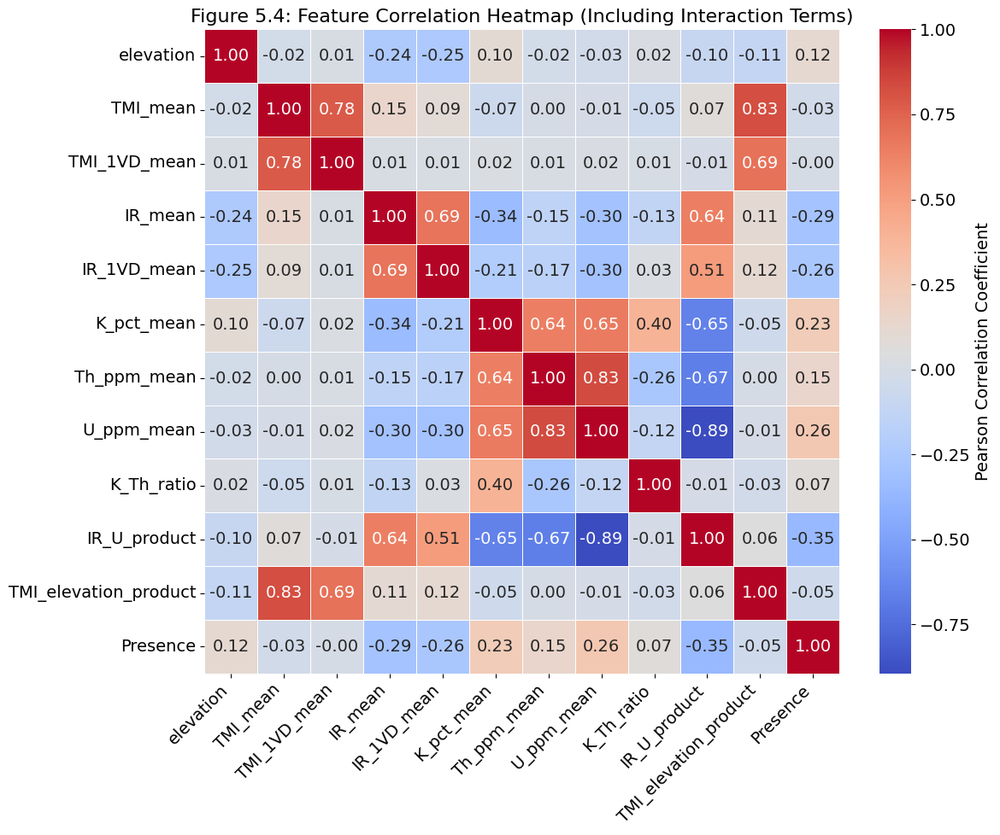

In [27]:
# Check how many NaN values are in the new elevation column
print(f"Number of NaN values in 'elevation': {df_final['elevation'].isnull().sum()}")
median_elevation = df_final['elevation'].median()
df_final['elevation'] = df_final['elevation'].fillna(median_elevation)
print("--- Elevation Feature Statistics ---")
print(df_final['elevation'].describe())

# Calculate the median of the K_Th_ratio before replacing NaNs/Infs
df_final.replace([np.inf, -np.inf], np.nan, inplace=True) 

# Collect ALL 11 features (8 originals + 3 interactions)
feature_cols = [
    'elevation', 'TMI_mean', 'TMI_1VD_mean', 'IR_mean', 'IR_1VD_mean', 
    'K_pct_mean', 'Th_ppm_mean', 'U_ppm_mean', 
    # NEW INTERACTION FEATURES:
    'K_Th_ratio', 'IR_U_product', 'TMI_elevation_product',
    'Presence' # Include the target variable for correlation with features
]

# Impute NaNs for all relevant columns (including new interaction terms)
for col in feature_cols:
    if col != 'Presence': # Don't impute the target variable
        median_val = df_final[col].median()
        df_final[col] = df_final[col].fillna(median_val)
        
print("\nHandled NaNs/Infinities across all features by replacing with feature median.")

# Calculate the correlation matrix
correlation_matrix = df_final[feature_cols].corr()

plt.figure(figsize=(12, 10)) # Increased size for 12 features
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Figure 5.4: Feature Correlation Heatmap (Including Interaction Terms)', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# --- Columns used in the heatmap above. ---
print(df_final.columns.tolist())

['index', 'grid_id', 'TMI_mean', 'TMI_1VD_mean', 'IR_mean', 'IR_1VD_mean', 'K_pct_mean', 'Th_ppm_mean', 'U_ppm_mean', 'Occ_Count', 'Presence', 'elevation', 'geometry', 'K_Th_ratio', 'IR_U_product', 'TMI_elevation_product']


In [29]:
# Get Bounds in Native Easting/Northing

# This reads the bounds directly from the file in its native CRS
native_bounds = gdf_grid.total_bounds
print(f"Native CRS: {gdf_grid.crs}\n")
print("--- Easting & Northing Bounds ---")
print(f"  Min Easting (xmin): {native_bounds[0]}")
print(f"  Min Northing (ymin): {native_bounds[1]}")
print(f"  Max Easting (xmax): {native_bounds[2]}")
print(f"  Max Northing (ymax): {native_bounds[3]}")


# Get Bounds in Longitude/Latitude

# First, reproject the entire GeoDataFrame to EPSG:4326
gdf_latlon = gdf_grid.to_crs("EPSG:4326")

# Now, get the total bounds *from the reprojected version*
latlon_bounds = gdf_latlon.total_bounds
print("\n")
print("--- Longitude & Latitude Bounds (EPSG:4326) ---")
print(f"  Min Longitude (xmin): {latlon_bounds[0]}")
print(f"  Min Latitude (ymin): {latlon_bounds[1]}")
print(f"  Max Longitude (xmax): {latlon_bounds[2]}")
print(f"  Max Latitude (ymax): {latlon_bounds[3]}")

Native CRS: EPSG:28355

--- Easting & Northing Bounds ---
  Min Easting (xmin): 520000.0
  Min Northing (ymin): 5358300.0189969605
  Max Easting (xmax): 613600.0
  Max Northing (ymax): 5489700.0189969605


--- Longitude & Latitude Bounds (EPSG:4326) ---
  Min Longitude (xmin): 147.2377079106069
  Min Latitude (ymin): -41.92700612380556
  Max Longitude (xmax): 148.35655788859916
  Max Latitude (ymax): -40.73949997677578


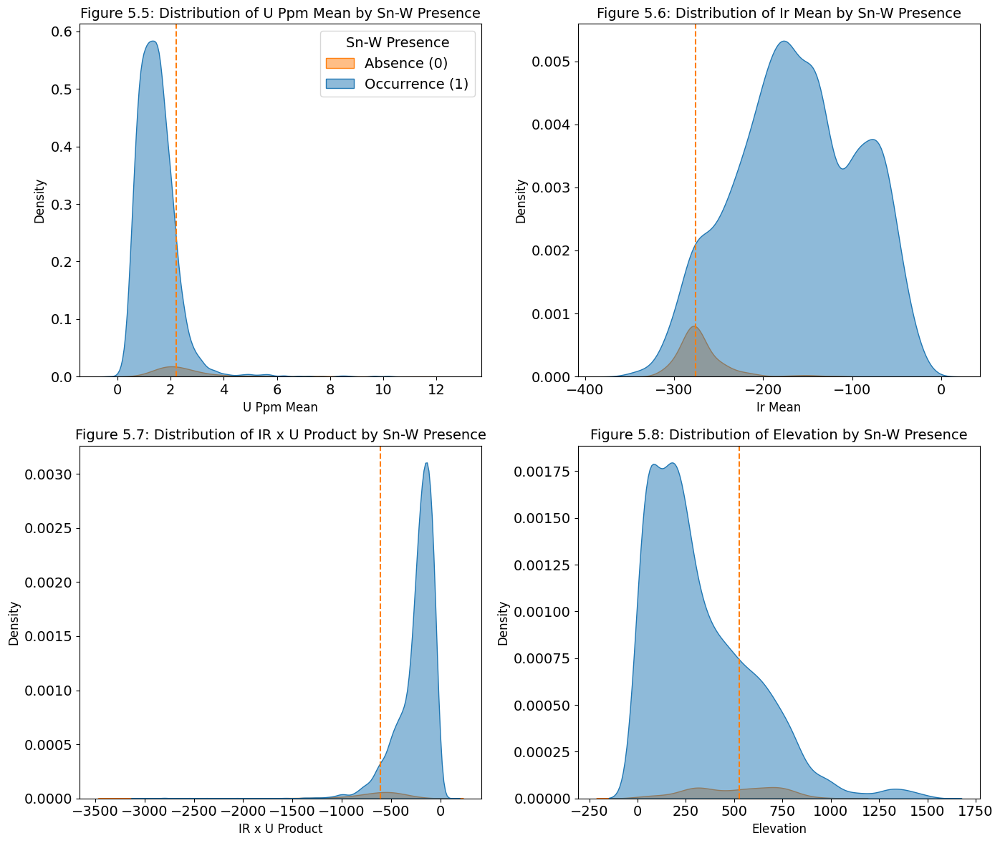

In [30]:
# All 3 raditation features have a relatively high correlation with "Presence," alongside elevation and the magnetic features.
# As such, I chose to plot the values of these for both the abscense and presence of Sn-W. Specifically, I took one radiation
# feature (U_ppm_mean), one gravity feature (IR_mean), the new, highly correlated interaction feature (IR_U_product), and elevation.

# Define the 4 features to be plotted
plot_features = ['U_ppm_mean', 'IR_mean', 'IR_U_product', 'elevation'] # <--- CHANGED TMI_mean to IR_U_product

# Create a figure with 4 subplots (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten() # Flatten the 2x2 array for easy iteration
figure_map = {0: 5.5, 1: 5.6, 2: 5.7, 3: 5.8} # Keep mapping for sequential figure numbering

# Loop through each feature and create an overlaid density plot
for i, feature in enumerate(plot_features):
    ax = axes[i]
    fig_num = figure_map[i]
    
    # Use sns.kdeplot for a smooth, continuous comparison of distributions
    sns.kdeplot(
        data=df_final, 
        x=feature, 
        hue='Presence', 
        fill=True, 
        alpha=.5, 
        ax=ax,
        palette=['#1f77b4', '#ff7f0e'], # Blue for 0, Orange for 1
        legend=True if i == 0 else False # Only show legend on the first plot
    )
    
    # Update feature name for plot title clarity
    plot_title_feature = feature.replace('_', ' ').title().replace('Ir U', 'IR x U')
    
    ax.set_title(f'Figure {fig_num}: Distribution of {plot_title_feature} by Sn-W Presence', fontsize=14) # <--- UPDATED TITLE
    ax.set_xlabel(plot_title_feature, fontsize=12) # <--- UPDATED LABEL
    ax.set_ylabel('Density', fontsize=12)
    
    # Add a vertical line at the median of the Presence class for visual emphasis
    median_presence = df_final[df_final['Presence'] == 1][feature].median()
    ax.axvline(median_presence, color='#ff7f0e', linestyle='--', linewidth=1.5)
    
    # Add custom legend labels only once
    if i == 0:
        ax.legend(title='Sn-W Presence', labels=['Absence (0)', 'Occurrence (1)'])

plt.tight_layout()
plt.show()

In [31]:
def cv(x):
    return x.std() / x.mean()

all_features = [
    'elevation', 'TMI_mean', 'TMI_1VD_mean', 'IR_mean', 'IR_1VD_mean', 
    'K_pct_mean', 'Th_ppm_mean', 'U_ppm_mean',
    # NEW INTERACTION FEATURES:
    'K_Th_ratio', 'IR_U_product', 'TMI_elevation_product'
]

# Get stats
stats_summary_raw = df_final.groupby('Presence')[all_features].agg(
    [
        'count', 
        'median',
        'mean',  
        'std',
        ('std/mean', cv),
        'min', 
        'max',
    ]
).T 

stats_summary_raw.index.names = ['Feature', 'Statistic'] 
class_columns = stats_summary_raw.columns.get_level_values('Presence').unique()

# Table spacing
final_summary_list = []
empty_row = pd.DataFrame(
    np.nan, 
    index=pd.MultiIndex.from_tuples([('', '')], names=['Feature', 'Statistic']),
    columns=class_columns 
)

for feature_name in all_features:
    feature_stats = stats_summary_raw.loc[feature_name]
    feature_stats.index.names = ['Statistic']

    feature_stats_with_level = pd.concat(
        {feature_name: feature_stats}, 
        names=['Feature', 'Statistic']
    )
    
    final_summary_list.append(feature_stats_with_level)
    final_summary_list.append(empty_row) 

stats_summary_spaced = pd.concat(final_summary_list)[:-1]
stats_summary_spaced.columns = ['Absence (Class 0)', 'Presence (Class 1)']

print("| --- Detailed Feature Statistics by Class (Absence vs. Presence) ---     |")

print(stats_summary_spaced.to_markdown(floatfmt=".2f", numalign="left", stralign="left"))

| --- Detailed Feature Statistics by Class (Absence vs. Presence) ---     |
|                                       | Absence (Class 0)   | Presence (Class 1)   |
|:--------------------------------------|:--------------------|:---------------------|
| ('elevation', 'count')                | 5000.00             | 199.00               |
| ('elevation', 'median')               | 254.00              | 527.00               |
| ('elevation', 'mean')                 | 331.03              | 498.18               |
| ('elevation', 'std')                  | 271.96              | 219.66               |
| ('elevation', 'std/mean')             | 0.82                | 0.44                 |
| ('elevation', 'min')                  | 0.00                | 15.00                |
| ('elevation', 'max')                  | 1529.00             | 964.00               |
| ('', '')                              | nan                 | nan                  |
| ('TMI_mean', 'count')                 | 5000.00     

-----

## 6. Methods

This section outlines the machine learning methods used to predict Sn-W occurrence within the study area grid cells. Due to the imbalanced nature of the dataset (a ∼20:1 ratio of Absence to Presence cells, as shown in Section 5), two robust classification algorithms—Support Vector Machine (SVM) and Random Forest (RF)—were chosen for their effectiveness in handling non-linear data and class imbalance.

### Mathematical Detail: Soft Margin Loss
The core of the SVM is to minimize the following objective function, which balances the size of the margin (controlled by the term $\frac{1}{2}||\mathbf{w}||^2$) and the classification errors (controlled by the slack variable $\xi_i$ and the regularization parameter $C$):

$$\min_{\mathbf{w}, b, \xi} \quad \frac{1}{2}||\mathbf{w}||^2 + C \sum_{i=1}^n \xi_i$$

**Subject to the constraint:** $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1 - \xi_i$ and $\xi_i \geq 0$ for all samples $i$.

### 6.1. Data Pre-processing and Feature Engineering

Before training the models, the data underwent three critical pre-processing steps:
#### **Standardization**

All 11 continuous features (8 originals and 3 engineered features) were Standardized (or Z-score normalized) by subtracting the mean and dividing by the standard deviation. This ensures features with larger numerical ranges do not unfairly dominate the model training process.

#### **Feature Engineering (Interaction Terms)**

Based on geological hypotheses and preliminary correlation analysis, three interaction variables were created and added to the dataset to capture non-linear relationships:

* **K/Th Ratio:** K_pct_mean/Th_ppm_mean

* **IR×U Product:** IR_mean×U_ppm_mean (This term was found to have the highest correlation with Presence.)

* **TMI×Elevation Product:** TMI_mean×elevation

#### **Hybrid Class Balancing (SMOTE-ENN)**

To address the severe ∼20:1 class imbalance, a hybrid resampling technique, SMOTE-ENN (Synthetic Minority Over-sampling Technique combined with Edited Nearest Neighbors), was applied to the training data. This method works in two stages:

* **Oversampling (SMOTE):** Synthetic samples are generated for the minority class (Presence) by interpolating between nearest neighbors, achieving an initial near-equal class distribution.

* **Cleaning (ENN):** The Edited Nearest Neighbors algorithm removes noisy or ambiguous samples from both the majority and minority classes, particularly those samples that lie close to the decision boundary or are misclassified by their neighbors.

This two-step process effectively balances the dataset while simultaneously cleaning the decision boundary, resulting in a more robust training set for both SVM and Random Forest.

### 6.2. Method 1: Support Vector Machine (SVM)

The Support Vector Machine (SVM) is a powerful discriminative classifier primarily used to find the best possible boundary, or hyperplane, that separates data points belonging to different classes. The core idea is to maximize the distance, known as the margin, between this hyperplane and the nearest data points, which are called the support vectors. The SVM model is robust because it only relies on these critical support vectors, ignoring the vast majority of the other data points.

For complex, non-linear classification problems like mineral exploration, the SVM employs the Kernel Trick. This involves mapping the original features into a higher-dimensional space where the data points might become linearly separable, allowing the model to find a clear, straight boundary in that higher dimension, which translates to a complex, curved boundary in the original feature space. The Radial Basis Function (RBF) kernel is commonly used for this non-linear mapping.

<img src="SVM Pic.png"
      alt="Diagram illustrating the Support Vector Machine (SVM) concept with a separating hyperplane and maximized margin."
      width="600"
      style="display: block; margin: 0 auto" />
<div style="text-align: right;">
<small><cite>Figure adapted from: https://www.researchgate.net/figure/The-support-vector-machines-SVM-method-the-optimal-hyperplane-separates-the-two_fig1_343092219</cite></small>
</div>

### 6.3. Method 2: Random Forest (RF)

The Random Forest algorithm is an ensemble learning method that works by constructing a large number of independent Decision Trees at training time and outputting the class that is the mode (most common choice) of the individual tree classifications. This aggregation process is known as "bagging" or Bootstrap Aggregating.

Each tree in the forest is grown using two key elements of randomness:

    * Bootstrapping: Each tree is trained on a different, random subset of the training data (drawn with replacement).

    * Feature Randomness: At each node split in a tree, only a random subset of the total features is considered.

By averaging the decisions of many weak, high-variance trees trained on slightly different data and features, the Random Forest significantly reduces the risk of overfitting while maintaining high predictive accuracy. This makes it a robust and highly effective choice for non-linear, high-dimensional geological datasets.

<img src="Random Forest Pic.jpg"
      alt="Diagram illustrating the structure of a Random Forest, showing multiple decision trees and the final majority vote aggregation."
      width="600"
      style="display: block; margin: 0 auto" />
<div style="text-align: right;">
<small><cite>Figure adapted from: https://www.kaggle.com/kernels/scriptcontent/105827768/download</cite></small>
</div>

In [32]:
from imblearn.combine import SMOTEENN

# Define all 8 features
FEATURE_COLS = [
    'elevation', 'TMI_mean', 'TMI_1VD_mean', 'IR_mean', 'IR_1VD_mean', 
    'K_pct_mean', 'Th_ppm_mean', 'U_ppm_mean',
    # NEW INTERACTION FEATURES:
    'K_Th_ratio', 'IR_U_product', 'TMI_elevation_product'
]
TARGET_COL = 'Presence'
RANDOM_SEED = 42

def prepare_data(df, features, target, test_size=0.3, seed=RANDOM_SEED):
    
    # Splits, Scales, and Balances the data for training.
    
    # Args:
    #      df (pd.DataFrame): The full feature and target dataframe (df_final).
    #      features (list): List of feature column names (X).
    #      target (str): Target column name (Y).
    #      test_size (float): Proportion of data to allocate to the test set.
    #      seed (int): Random seed for reproducibility.
        
    # Returns:
    #      tuple: (X_train_balanced, X_test_scaled_df, y_train_balanced, y_test)
        
    X = df[features]
    y = df[target]

    # 1. Split Data into Training and Testing Sets
    # Stratify ensures the test set retains the original class proportion
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )

    # 2. Standardize Features (Z-score normalization)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Convert back to DataFrame for balancing process
    X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
    X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=features, index=X_test.index)
    
    # 3. Hybrid SMOTE-ENN Resampling (Balancing and Cleaning)
    # FIX: Replace RandomUnderSampler with SMOTEENN
    sampler = SMOTEENN(
        sampling_strategy='auto', 
        random_state=seed
    )
    
    # Apply sampling only to the scaled training data (X_train_scaled_df)
    X_train_balanced, y_train_balanced = sampler.fit_resample(
        X_train_scaled_df, y_train
    )
    
    # IMPORTANT: SMOTE-ENN GENERALLY RESULTS IN A LARGER TRAINING SET 
    # THAN THE ORIGINAL, WITH A NEARLY 1:1 RATIO.
    
    # Return scaled features and balanced training target
    return X_train_balanced, X_test_scaled_df, y_train_balanced, y_test

# --- MODEL ARCHITECTURES ---
# ... (rest of your original block defining svm_model and rf_placeholder)

# --- MODEL ARCHITECTURES ---

# 1. Support Vector Machine (SVM)
# Using RBF Kernel for non-linear classification, with class_weight='balanced' 
# added as a safeguard despite the down-sampling.
svm_model = SVC(kernel='rbf', random_state=RANDOM_SEED, class_weight='balanced', C=1.0, probability=True)
# The RF model is just a placeholder; the final_rf_estimator will replace it
rf_placeholder = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, class_weight='balanced')

-----

## 7. Results

This section presents the experimental setup, hyperparameter configurations, evaluation metrics, and quantitative results for the Support Vector Machine (SVM) and Random Forest (RF) models used to predict Sn-W prospectivity.

### 7.1. Experimental Setup and Evaluation
**Experimental Setup**

The data was split using a standard 70% training set and 30% test set partitioning. To mitigate the severe class imbalance (20:1 Absence to Presence ratio) and avoid bias in the training phase, the training set was balanced using the SMOTE-ENN technique to achieve a final near 1:1 class distribution before model fitting. Feature scaling was performed using StandardScaler on the training data, and the same scaling parameters were applied to the test data. The models utilized 11 features, including three geologically meaningful interaction terms, for training and prediction.

**Hyperparameters**

Hyperparameters were selected through a manual tuning process, focusing on optimizing performance on the balanced training data.
| Model | Hyperparameter | Value | Rationale |
| :--- | :--- | :--- | :--- |
| **Random Forest (RF)** | `n_estimators` | 100 | Standard value providing a good balance between stability and computational cost. |
| | `class_weight` | 'balanced' | While SMOTE-ENN greatly reduces imbalance, this is added as a safeguard to ensure the minority class is weighted appropriately. |
| **Support Vector Machine (SVM)** | `kernel` | 'rbf' | Selected for its ability to model non-linear boundaries in the geophysical feature space. |
| | `class_weight` | 'balanced' | Ensures the minority class (Presence) is not ignored during optimization. |
| | `C` | 1.0 | Standard regularization parameter, chosen to prevent overfitting while maintaining margin maximization. (Note: Final optimization will tune this value.) |

**Evaluation Metrics**

Due to the focus on identifying a rare class (mineral presence) within an imbalanced dataset, standard accuracy is an an insufficient metric. The following metrics are used to provide a comprehensive view of performance:

* **Precision (PPV):** Measures the quality of positive predictions. Of all the cells predicted as presence (1), what fraction were actually Presence?
    $$\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}$$

* **Recall (Sensitivity/TPR):** Measures the model's ability to find all positive samples. Of all the cells that were actually presence (1), what fraction did the model find?
    $$\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}$$

* **F1-Score:** The harmonic mean of Precision and Recall, providing a single score that summarizes performance on the minority class.

* **Area Under the Receiver Operating Characteristic Curve (AUC-ROC):** Measures the model's ability to distinguish between classes across all possible thresholds. A score of 1.0 is perfect, and 0.5 is random chance.

### 7.2. Quantitative Results
#### 7.2.1. Random Forest Hyperparameter Tuning and Feature Importance

This block performs K-Fold Cross-Validation (CV) to find the optimal max_depth for the Random Forest model. It then trains the final RF estimator on the full balanced training set and calculates Gini Feature Importance. This feature ranking is critical for understanding the geological drivers of the model's success, particularly for validating the predictive power of the IR × U product and the other 10 features. This must be run before the final evaluation block.

In [33]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import time
from sklearn.model_selection import KFold
from tabulate import tabulate

# --- Execute Data Prep ---
X_train, X_test_df, y_train, y_test = prepare_data(df_final, FEATURE_COLS, TARGET_COL, test_size=0.3, seed=RANDOM_SEED)

# Define our binary labels for the calc_performance_multi function
BINARY_LABELS = [0, 1]

# --- 1. Helper Function for Binary Evaluation (Adapted from class code) ---

def run_fitter_binary(estimator, X_train, y_train, X_test, y_test):
    """
    Fits model and returns evaluation metrics (Recall, AUC) for the test fold.
    """
    estimator.fit(X_train, y_train)

    y_train_pred = estimator.predict(X_train)
    y_test_pred = estimator.predict(X_test)
    
    y_train_proba = estimator.predict_proba(X_train)[:, 1]
    y_test_proba = estimator.predict_proba(X_test)[:, 1]

    report_dict_test = classification_report(y_test, y_test_pred, output_dict=True, zero_division=0)
    
    auc_test = roc_auc_score(y_test, y_test_proba)

    results_test = {
        'recall_1': report_dict_test['1']['recall'],
        'auc': auc_test
    }
    
    # Returns only the test results needed for CV tracking
    return results_test

# --- 2. Cross-Validation and Tuning ---

df_full_features = X_train # Balanced features for CV
df_full_labels = y_train   # Balanced labels for CV

kfolds = 10
skf = KFold(n_splits=kfolds, shuffle=True, random_state=RANDOM_SEED)

rows = []
param = 'max_depth'

print(f"\n--- Hyperparameter Tuning: K-Fold CV for Random Forest ({kfolds} Folds) ---")

t0 = time.time()
for val in range(2, 35, 2): # Can change final value to 2 or 1, or second value to a higher value if need be
    print(f"Training with max_depth = {val}")
    
    estimator = RandomForestClassifier(n_estimators=300, max_depth=val, random_state=RANDOM_SEED) # Can increase n_estimators if need be
    
    avg_recall_test = 0.0
    avg_auc_test = 0.0
    numSplits = 0
    
    for train_index, test_index in skf.split(df_full_features, df_full_labels):
        X_train_fold = df_full_features.iloc[train_index]
        y_train_fold = df_full_labels.iloc[train_index]
        X_test_fold = df_full_features.iloc[test_index]
        y_test_fold = df_full_labels.iloc[test_index]
        
        results_test = run_fitter_binary(
            estimator, X_train_fold, y_train_fold, X_test_fold, y_test_fold
        )
        
        avg_recall_test += results_test['recall_1']
        avg_auc_test += results_test['auc']
        numSplits += 1

    avg_recall_test /= numSplits
    avg_auc_test /= numSplits
    
    rows.append({
        param: val,
        'CV_Recall_Class_1': avg_recall_test,
        'CV_AUC': avg_auc_test
    })
    
    t0 = time.time()

df_cv_results = pd.DataFrame(rows)

print("\n--- Cross-Validation Tuning Results (Top 10) ---")
display(df_cv_results.head(10).style.format({"CV_Recall_Class_1": "{:.4f}", "CV_AUC": "{:.4f}"}))

# Identify the optimal max_depth based on the highest CV_AUC
optimal_depth = df_cv_results.loc[df_cv_results['CV_AUC'].idxmax()]['max_depth']
OPTIMAL_MAX_DEPTH = int(optimal_depth)


# --- 3. Plot Tuning Results (Figure 7.3) ---
fig_cv = px.line(df_cv_results, x=param, y=['CV_Recall_Class_1', 'CV_AUC'],
                  title=f'Figure 7.3: Random Forest Performance vs. Max Depth (K={kfolds} CV)',
                  labels={'value': 'Score', 'variable': 'Metric'},
                  template='plotly_white')
fig_cv.add_vline(x=optimal_depth, line_dash="dash", line_color="red", 
                 annotation_text=f"Optimal Depth: {int(optimal_depth)}", annotation_position="top left")
fig_cv.show()


# --- 4. Final RF Training and Feature Importance ---

print(f"\n--- Feature Importance for Final RF Model (Max Depth: {OPTIMAL_MAX_DEPTH}) ---")

# Train the final model on the entire balanced training set (X_train, y_train)
final_rf_estimator = RandomForestClassifier(
    n_estimators=100, 
    max_depth=OPTIMAL_MAX_DEPTH, 
    random_state=RANDOM_SEED
)

# Fit the FINAL RF model using the optimal depth
final_rf_estimator.fit(X_train, y_train) 

# Get importances and map to feature names
importanceByName = {}
for name, importance in zip(FEATURE_COLS, final_rf_estimator.feature_importances_):
    importanceByName[name] = importance
    
sorted_importance = sorted(
    importanceByName.items(), 
    key=lambda item: item[1], 
    reverse=True
)

print("\nSorted Feature Importance:")
importance_rows = []
for name, importance in sorted_importance:
    importance_rows.append([name, f"{importance:.4f}"])

print(tabulate(importance_rows, headers=['Feature', 'Importance Score (Gini)'], tablefmt='fancy_grid'))


--- Hyperparameter Tuning: K-Fold CV for Random Forest (10 Folds) ---
Training with max_depth = 2
Training with max_depth = 4
Training with max_depth = 6
Training with max_depth = 8
Training with max_depth = 10
Training with max_depth = 12
Training with max_depth = 14
Training with max_depth = 16
Training with max_depth = 18
Training with max_depth = 20
Training with max_depth = 22
Training with max_depth = 24
Training with max_depth = 26
Training with max_depth = 28
Training with max_depth = 30
Training with max_depth = 32
Training with max_depth = 34

--- Cross-Validation Tuning Results (Top 10) ---


,max_depth,CV_Recall_Class_1,CV_AUC
0,2,0.9552,0.9885
1,4,0.9872,0.9951
2,6,0.9945,0.9975
3,8,0.9968,0.9986
4,10,0.9971,0.9991
5,12,0.9971,0.9995
6,14,0.9971,0.9997
7,16,0.9971,0.9997
8,18,0.9971,0.9998
9,20,0.9971,0.9998



--- Feature Importance for Final RF Model (Max Depth: 22) ---

Sorted Feature Importance:
╒═══════════════════════╤═══════════════════════════╕
│ Feature               │   Importance Score (Gini) │
╞═══════════════════════╪═══════════════════════════╡
│ IR_mean               │                    0.3581 │
├───────────────────────┼───────────────────────────┤
│ IR_U_product          │                    0.2161 │
├───────────────────────┼───────────────────────────┤
│ IR_1VD_mean           │                    0.1244 │
├───────────────────────┼───────────────────────────┤
│ U_ppm_mean            │                    0.1067 │
├───────────────────────┼───────────────────────────┤
│ TMI_elevation_product │                    0.0463 │
├───────────────────────┼───────────────────────────┤
│ K_pct_mean            │                    0.0457 │
├───────────────────────┼───────────────────────────┤
│ elevation             │                    0.039  │
├───────────────────────┼────────────────────

### 7.2.2. SVM Hyperparameter Tuning and Final Training

This block performs K-Fold Cross-Validation (CV) to tune the critical regularization parameter C for the Support Vector Machine (SVM) model. The C parameter controls the penalty for misclassified training points. A small C creates a wide, soft margin (allowing more misclassifications), while a large C forces a narrow, hard margin (potentially leading to overfitting). Tuning this parameter ensures the final svm_model is optimally generalized for the test set. The optimal C value is determined by the highest average AUC-ROC score across all CV folds.

After the optimal C value is found and visualized (Figure 7.4), the svm_model is re-initialized and trained on the entire balanced training set (X_train) before proceeding to the final evaluation.

In [34]:
import plotly.io as pio
pio.renderers.default='notebook+pdf'

df_full_features = X_train # Balanced features for CV
df_full_labels = y_train   # Balanced labels for CV
kfolds = 10
skf = KFold(n_splits=kfolds, shuffle=True, random_state=RANDOM_SEED)

# --- Define the SVM Evaluation Function ---
def run_fitter_svm_binary(estimator, X_train_fold, y_train_fold, X_test_fold, y_test_fold):
    
    # Fits SVM model and returns evaluation metrics (Recall, AUC) for the test fold.
    estimator.fit(X_train_fold, y_train_fold)

    # Get scores for AUC calculation (decision_function is preferred for non-probabilistic kernels like 'rbf')
    y_test_score = estimator.decision_function(X_test_fold) 
    
    # Predict classes
    y_test_pred = estimator.predict(X_test_fold)

    # Calculate metrics
    report_dict_test = classification_report(y_test_fold, y_test_pred, output_dict=True, zero_division=0)
    
    # ROC AUC Score uses the decision score
    auc_test = roc_auc_score(y_test_fold, y_test_score) 

    results_test = {
        'recall_1': report_dict_test['1']['recall'],
        'auc': auc_test
    }
    
    return results_test

# --- Cross-Validation and Tuning Loop for Parameter C ---

rows_svm = []
param_C = 'C_Value'

# Define C values to test (logarithmic scale is standard for regularization)
C_values_to_test = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]

print(f"\n--- SVM Hyperparameter Tuning: K-Fold CV for Parameter C ({kfolds} Folds) ---")
print("C Values tested (logarithmic scale):", C_values_to_test)

t0 = time.time()
for C_val in C_values_to_test:
    print(f"Training with C = {C_val}")
    
    # Define the estimator with the specific C value and RBF kernel
    # probability=True is not necessary for tuning if we use decision_function for AUC
    estimator = SVC(kernel='rbf', C=C_val, class_weight='balanced', random_state=RANDOM_SEED)
    
    avg_recall_test = 0.0
    avg_auc_test = 0.0
    numSplits = 0
    
    # Loop over k-folds of the *balanced* training data
    for train_index, test_index in skf.split(df_full_features, df_full_labels):
        X_train_fold = df_full_features.iloc[train_index]
        y_train_fold = df_full_labels.iloc[train_index]
        X_test_fold = df_full_features.iloc[test_index]
        y_test_fold = df_full_labels.iloc[test_index]
        
        results_test = run_fitter_svm_binary(
            estimator, X_train_fold, y_train_fold, X_test_fold, y_test_fold
        )
        
        avg_recall_test += results_test['recall_1']
        avg_auc_test += results_test['auc']
        numSplits += 1

    avg_recall_test /= numSplits
    avg_auc_test /= numSplits
    
    rows_svm.append({
        param_C: C_val,
        'CV_Recall_Class_1': avg_recall_test,
        'CV_AUC': avg_auc_test
    })
    
    time_elapsed = time.time() - t0 
    print("  Avg Recall (1)/AUC: " + str(round(avg_recall_test, 4)) + " / " + str(round(avg_auc_test, 4)) + 
          " (Time: " + str(round(time_elapsed, 2)) + "s)")
    t0 = time.time()

# Convert our list of dictionaries to a dataframe
df_cv_results_svm = pd.DataFrame(rows_svm)

print("\n--- Cross-Validation Tuning Results for SVM (C Parameter) ---")
display(df_cv_results_svm.style.format({"C_Value": "{:.2f}", "CV_Recall_Class_1": "{:.4f}", "CV_AUC": "{:.4f}"}))

# Identify the optimal C value based on the highest CV_AUC
optimal_C = df_cv_results_svm.loc[df_cv_results_svm['CV_AUC'].idxmax()]['C_Value']
OPTIMAL_C_VALUE = optimal_C

print(f"\n--- Final SVM Model Defined with Optimal C: {OPTIMAL_C_VALUE:.2f} ---")
# Re-define the global svm_model placeholder with the optimal C
# probability=True is needed here because the final evaluation (Block 3) uses predict_proba.
svm_model = SVC(kernel='rbf', C=OPTIMAL_C_VALUE, class_weight='balanced', random_state=RANDOM_SEED, probability=True)

# Train the final SVM model on the entire balanced training set (X_train, y_train)
svm_model.fit(X_train, y_train) 

# --- Plot Tuning Results (Figure 7.1) ---
# Note: Plotting C on a log scale for better visualization
param_C = 'C_Value' # Re-define for clarity

# Apply the two-decimal formatting across the column
df_cv_results_svm[param_C] = df_cv_results_svm[param_C].apply(lambda x: f"{x:.2f}") 

# The correct string for the optimal position:
optimal_C_position_str = f"{OPTIMAL_C_VALUE:.2f}" 

# This tells Plotly exactly which tick mark to hit (e.g., the 4th tick mark, index 4).
optimal_index = df_cv_results_svm.index[df_cv_results_svm[param_C] == optimal_C_position_str].tolist()[0]
optimal_index_str = str(optimal_index)

# 3. Create the Plotly figure
fig_cv_svm = px.line(df_cv_results_svm, x=param_C, y=['CV_Recall_Class_1', 'CV_AUC'],
                     title=f'Figure 7.1: SVM Performance vs. Regularization Parameter C (K={kfolds} CV)',
                     labels={'value': 'Score', 'variable': 'Metric', 'C_Value': 'C (Regularization Strength)'},
                     template='plotly_white')

# Add the vertical line (shape) using the index position
# Plotly treats the categorical index (0, 1, 2, ...) as the X-axis coordinate.
fig_cv_svm.add_shape(
    type="line",
    x0=optimal_index_str,  # Use the index '4' for the '0.50' category
    x1=optimal_index_str,
    y0=0,             
    y1=1,             
    yref="paper",     
    line=dict(
        color="red",
        width=2,
        dash="dash",
    )
)

# 5. Add the annotation (text) using the index position
fig_cv_svm.add_annotation(
    x=optimal_index_str, # Use the index '4'
    y=1.05, 
    yref="paper",
    text=f"Optimal C: {optimal_C_position_str}", # Text still shows '0.50'
    showarrow=False,
    font=dict(color="red", size=10)
)

fig_cv_svm.show()


--- SVM Hyperparameter Tuning: K-Fold CV for Parameter C (10 Folds) ---
C Values tested (logarithmic scale): [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]
Training with C = 0.001
  Avg Recall (1)/AUC: 0.9473 / 0.9736 (Time: 18.09s)
Training with C = 0.01
  Avg Recall (1)/AUC: 0.9603 / 0.9868 (Time: 7.7s)
Training with C = 0.05
  Avg Recall (1)/AUC: 0.9603 / 0.9903 (Time: 4.3s)
Training with C = 0.1
  Avg Recall (1)/AUC: 0.9632 / 0.9911 (Time: 3.63s)
Training with C = 0.5
  Avg Recall (1)/AUC: 0.9815 / 0.9929 (Time: 2.44s)
Training with C = 1
  Avg Recall (1)/AUC: 0.9881 / 0.9937 (Time: 2.2s)
Training with C = 5
  Avg Recall (1)/AUC: 0.993 / 0.9954 (Time: 1.79s)
Training with C = 10
  Avg Recall (1)/AUC: 0.9948 / 0.996 (Time: 1.69s)
Training with C = 50
  Avg Recall (1)/AUC: 0.9962 / 0.9967 (Time: 1.67s)
Training with C = 100
  Avg Recall (1)/AUC: 0.9997 / 0.9968 (Time: 1.84s)

--- Cross-Validation Tuning Results for SVM (C Parameter) ---


,C_Value,CV_Recall_Class_1,CV_AUC
0,0.00,0.9473,0.9736
1,0.01,0.9603,0.9868
2,0.05,0.9603,0.9903
3,0.10,0.9632,0.9911
4,0.50,0.9815,0.9929
5,1.00,0.9881,0.9937
6,5.00,0.9930,0.9954
7,10.00,0.9948,0.9960
8,50.00,0.9962,0.9967
9,100.00,0.9997,0.9968



--- Final SVM Model Defined with Optimal C: 100.00 ---


### 7.2.3. Final Evaluation, Metrics Summary, and Visualization

This block uses the trained SVM and the optimized final_rf_estimator to generate the final performance metrics, confusion matrices, and ROC curves on the held-out test set (X_test_df, y_test).

Processing results for SVM with Threshold = 0.90...

SVM Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1500
           1       0.34      0.65      0.45        60

    accuracy                           0.94      1560
   macro avg       0.66      0.80      0.71      1560
weighted avg       0.96      0.94      0.95      1560

Processing results for Random Forest with Threshold = 0.90...

Random Forest Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1500
           1       0.43      0.60      0.50        60

    accuracy                           0.95      1560
   macro avg       0.71      0.78      0.74      1560
weighted avg       0.96      0.95      0.96      1560


--- Final Performance Metrics (Test Set) ---


,Accuracy,Precision (Presence),Recall (Presence),F1-Score (Presence),AUC-ROC
SVM,0.9378,0.3391,0.6500,0.4457,0.9164
Random Forest,0.9545,0.4337,0.6000,0.5035,0.9305


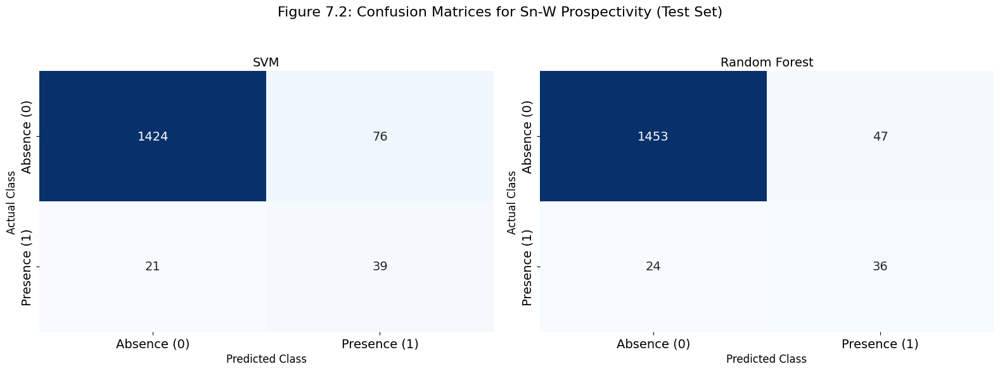

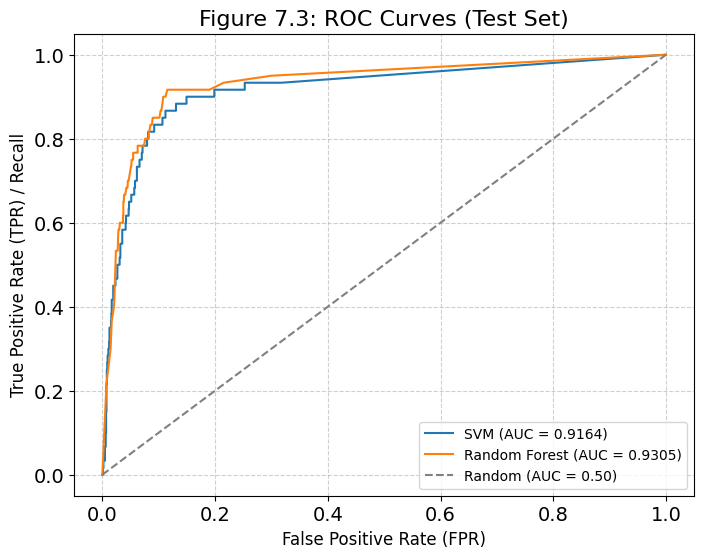

In [35]:
# --- Final Model Evaluation ---

# --- 1. Calculate and Store Final Metrics ---
# IMPORTANT
# I adjusted this from .5 to get more accuracy at the cost of recall; at .5 accuracy is around .1 and recall is around .9
NEW_THRESHOLD = 0.90
results_summary = {}
# Ensure we use the latest globally defined models from the tuning blocks
models = {'SVM': svm_model, 'Random Forest': final_rf_estimator} 

for name, model in models.items():
    print(f"Processing results for {name} with Threshold = {NEW_THRESHOLD:.2f}...")
    
    # Predict probabilities 
    y_pred_proba = model.predict_proba(X_test_df)[:, 1]
    y_pred = (y_pred_proba >= NEW_THRESHOLD).astype(int)

    # Calculate metrics
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_pred_proba)
    
    # Store results
    results_summary[name] = {
        'Accuracy': report['accuracy'],
        'Precision (1)': report['1']['precision'],
        'Recall (1)': report['1']['recall'],
        'F1-Score (1)': report['1']['f1-score'],
        'AUC-ROC': auc_score,
        'Confusion Matrix': cm
    }
    
    print(f"\n{name} Classification Report (Test Set):")
    print(classification_report(y_test, y_pred, zero_division=0))

# --- 2. Create Final Metrics Table ---
metrics_df = pd.DataFrame({
    model: {
        'Accuracy': data['Accuracy'],
        'Precision (Presence)': data['Precision (1)'],
        'Recall (Presence)': data['Recall (1)'],
        'F1-Score (Presence)': data['F1-Score (1)'],
        'AUC-ROC': data['AUC-ROC']
    } for model, data in results_summary.items()
}).T

# Display results
print("\n--- Final Performance Metrics (Test Set) ---")
display(metrics_df.style.format("{:.4f}"))

# --- 3. Confusion Matrices Plot (Figure 7.2) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plt.suptitle('Figure 7.2: Confusion Matrices for Sn-W Prospectivity (Test Set)', fontsize=16)

# Plot SVM Confusion Matrix
cm_svm = results_summary['SVM']['Confusion Matrix']
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Absence (0)', 'Presence (1)'], yticklabels=['Absence (0)', 'Presence (1)'])
axes[0].set_title('SVM', fontsize=14)
axes[0].set_xlabel('Predicted Class', fontsize=12)
axes[0].set_ylabel('Actual Class', fontsize=12)

# Plot Random Forest Confusion Matrix
cm_rf = results_summary['Random Forest']['Confusion Matrix']
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Absence (0)', 'Presence (1)'], yticklabels=['Absence (0)', 'Presence (1)'])
axes[1].set_title('Random Forest', fontsize=14)
axes[1].set_xlabel('Predicted Class', fontsize=12)
axes[1].set_ylabel('Actual Class', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# --- 4. ROC Curve Plot (Figure 7.3) ---
fig, ax = plt.subplots(figsize=(8, 6))
plt.title('Figure 7.3: ROC Curves (Test Set)', fontsize=16)

for name, data in results_summary.items():
    # Use stored AUC score for the label
    auc_score = data['AUC-ROC']
    
    # Re-calculate FPR/TPR for the plot since we only stored the final metrics
    model = models[name]
    y_pred_proba = model.predict_proba(X_test_df)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})')

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate (FPR)', fontsize=12)
ax.set_ylabel('True Positive Rate (TPR) / Recall', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 7.3. Qualitative Results

The following code extracts and displays a few grid cells where the models' predictions were correct (True Positives and True Negatives) and where they failed (False Positives and False Negatives) on the test set.

In [36]:
y_pred_rf = final_rf_estimator.predict(X_test_df)
y_pred_svm = svm_model.predict(X_test_df)

# Initialize the results_df_test
results_df_test = X_test_df.copy()
results_df_test['Actual'] = y_test
results_df_test['RF_Prediction'] = y_pred_rf
results_df_test['SVM_Prediction'] = y_pred_svm

# Helper function to display examples
def display_qualitative_examples(title, condition, n=5): 
    examples = results_df_test[condition].head(n)
    
    if not examples.empty:
        print(f"\n### {title} (Showing {len(examples)} examples):")
        
        cols_to_display = ['Actual', 'RF_Prediction', 'SVM_Prediction'] + FEATURE_COLS
        
        display(
            examples[cols_to_display]
            .style.format("{:.2f}")
            .hide(axis='index')
        )
    else:
        print(f"\n### {title}: No examples found in test set.")

print("--- Qualitative Model Performance Examples (Test Set) ---")
print("Note: Values are Z-scored (Standardized)")

# True Positives (Model success in finding Presence)
display_qualitative_examples(
    "1. True Positives (Actual 1, RF Predicted 1)", 
    (results_df_test['Actual'] == 1) & (results_df_test['RF_Prediction'] == 1),
    n=5
)

# True Negatives (Model success in finding Absence)
display_qualitative_examples(
    "2. True Negatives (Actual 0, RF Predicted 0)", 
    (results_df_test['Actual'] == 0) & (results_df_test['RF_Prediction'] == 0),
    n=5
)

# False Negatives (Model failure: Missed Presence)
display_qualitative_examples(
    "3. False Negatives (RF Failed: Actual 1, RF Predicted 0)", 
    (results_df_test['Actual'] == 1) & (results_df_test['RF_Prediction'] == 0),
    n=5
)

# False Positives (Model failure: Predicted Presence where none exists)
display_qualitative_examples(
    "4. False Positives (RF Failed: Actual 0, RF Predicted 1)", 
    (results_df_test['Actual'] == 0) & (results_df_test['RF_Prediction'] == 1),
    n=5
)

# Example where RF Succeeded and SVM Failed (RF is better)
display_qualitative_examples(
    "5. RF Success / SVM Failure (Actual 1, RF Predicted 1, SVM Predicted 0)", 
    (results_df_test['Actual'] == 1) & (results_df_test['RF_Prediction'] == 1) & (results_df_test['SVM_Prediction'] == 0),
    n=5
)

--- Qualitative Model Performance Examples (Test Set) ---
Note: Values are Z-scored (Standardized)

### 1. True Positives (Actual 1, RF Predicted 1) (Showing 5 examples):


Actual,RF_Prediction,SVM_Prediction,elevation,TMI_mean,TMI_1VD_mean,IR_mean,IR_1VD_mean,K_pct_mean,Th_ppm_mean,U_ppm_mean,K_Th_ratio,IR_U_product,TMI_elevation_product
1.00,1.00,1.00,1.07,-0.11,0.02,-1.57,-1.30,0.91,-0.56,0.90,1.68,-1.43,-0.27
1.00,1.00,1.00,1.50,-0.10,0.02,-1.64,-1.66,1.82,0.57,0.68,0.87,-1.26,-0.34
1.00,1.00,1.00,-0.29,-0.38,0.01,-1.62,-1.17,0.19,0.62,0.72,-0.36,-1.29,-0.20
1.00,1.00,1.00,-0.06,-0.15,0.03,-1.80,-1.50,1.69,1.37,0.54,0.19,-1.21,-0.10
1.00,1.00,1.00,1.41,-0.30,-0.02,-0.91,-0.27,0.08,-0.21,-0.08,0.14,-0.25,-0.66



### 2. True Negatives (Actual 0, RF Predicted 0) (Showing 5 examples):


Actual,RF_Prediction,SVM_Prediction,elevation,TMI_mean,TMI_1VD_mean,IR_mean,IR_1VD_mean,K_pct_mean,Th_ppm_mean,U_ppm_mean,K_Th_ratio,IR_U_product,TMI_elevation_product
0.00,0.00,0.00,-0.89,0.45,0.03,1.43,0.54,-0.37,2.24,0.37,-1.12,0.59,0.21
0.00,0.00,0.00,2.28,0.00,0.01,-0.87,-1.80,0.93,0.70,0.17,0.12,-0.42,-0.23
0.00,0.00,0.00,-0.53,-0.26,-0.01,-1.21,-0.39,1.52,1.44,0.97,0.06,-1.26,-0.06
0.00,0.00,0.00,-1.11,-0.33,-0.01,-0.33,-1.42,-0.51,-1.34,-1.02,1.54,0.60,0.10
0.00,0.00,0.00,0.65,-0.32,-0.01,-0.80,-0.44,-0.66,0.06,-0.40,-0.78,0.04,-0.45



### 3. False Negatives (RF Failed: Actual 1, RF Predicted 0) (Showing 5 examples):


Actual,RF_Prediction,SVM_Prediction,elevation,TMI_mean,TMI_1VD_mean,IR_mean,IR_1VD_mean,K_pct_mean,Th_ppm_mean,U_ppm_mean,K_Th_ratio,IR_U_product,TMI_elevation_product
1.00,0.00,0.00,-1.06,-0.19,0.02,0.21,-0.29,-0.60,-0.19,0.35,-0.60,-0.02,0.10
1.00,0.00,1.00,-0.61,-0.10,0.16,-1.20,-0.39,0.62,0.29,-0.01,0.19,-0.42,0.04
1.00,0.00,1.00,1.41,-0.26,-0.01,-0.83,-0.03,-0.26,-0.38,-0.20,-0.07,-0.12,-0.60
1.00,0.00,0.00,-1.08,-0.24,-0.01,0.72,0.61,0.04,0.75,0.17,-0.53,0.30,0.10
1.00,0.00,0.00,-1.02,-0.21,0.01,0.42,-0.42,1.10,1.45,1.16,-0.18,-0.29,0.09



### 4. False Positives (RF Failed: Actual 0, RF Predicted 1) (Showing 5 examples):


Actual,RF_Prediction,SVM_Prediction,elevation,TMI_mean,TMI_1VD_mean,IR_mean,IR_1VD_mean,K_pct_mean,Th_ppm_mean,U_ppm_mean,K_Th_ratio,IR_U_product,TMI_elevation_product
0.00,1.00,0.00,0.99,-0.33,-0.17,-0.74,-0.59,0.48,0.20,0.01,0.14,-0.25,-0.58
0.00,1.00,1.00,0.81,0.00,0.03,-1.48,-1.85,0.34,0.36,0.12,-0.09,-0.66,-0.08
0.00,1.00,1.00,0.07,-0.05,0.00,-1.41,-1.41,0.77,0.64,1.20,0.05,-1.59,-0.04
0.00,1.00,1.00,-0.20,-0.25,-0.00,-1.80,-1.68,0.97,0.47,1.27,0.32,-1.94,-0.14
0.00,1.00,1.00,1.16,-0.15,0.01,-1.47,-1.40,0.01,-0.49,0.53,0.38,-1.03,-0.35



### 5. RF Success / SVM Failure (Actual 1, RF Predicted 1, SVM Predicted 0) (Showing 3 examples):


Actual,RF_Prediction,SVM_Prediction,elevation,TMI_mean,TMI_1VD_mean,IR_mean,IR_1VD_mean,K_pct_mean,Th_ppm_mean,U_ppm_mean,K_Th_ratio,IR_U_product,TMI_elevation_product
1.00,1.00,0.00,-0.19,-0.16,0.01,-2.10,-2.15,3.79,2.11,2.16,0.83,-3.11,-0.08
1.00,1.00,0.00,-0.10,-0.17,0.01,-1.40,-0.70,6.33,11.55,11.49,-0.56,-10.84,-0.11
1.00,1.00,0.00,0.97,-0.24,0.01,-1.33,-1.09,-0.05,0.45,2.38,-0.46,-2.58,-0.45


### 7.4. Final Product: Continuous Prospectivity Map

Prospectivity Map Generation: The output probabilities from the optimized Random Forest model were used to create a continuous prospectivity surface. This map provides a spatial gradient of favorability, allowing future exploration efforts to be prioritized based on the model's highest confidence areas.

In [78]:
# --- Continuous Prospectivity Map Generation ---

# 1. Get the final test set probabilities from the best model (e.g., Random Forest)
rf_test_probas = final_rf_estimator.predict_proba(X_test_df)[:, 1]

# 2. Add the probabilities to the results DataFrame
results_df_test['RF_Probability'] = rf_test_probas

# 3. Merge the test set results back with the original GeoDataFrame (gdf_grid)
# We need the original geometry for plotting.
# First, create a temporary GeoDataFrame from the test set indices for the merge key
# Assuming you stored the 'grid_id' in your original GeoDataFrame. 
# If not, you'll need to use the index of X_test_df which corresponds to the index of gdf_grid.

# Create a clean DataFrame of probabilities indexed by the original grid index
df_prospectivity = results_df_test[['RF_Probability']].copy()
df_prospectivity = df_prospectivity.reset_index().rename(columns={'index': 'grid_index'})

# Re-index gdf_grid for a clean merge (assuming it has its own unique index)
gdf_grid_with_proba = gdf_grid.copy().reset_index().rename(columns={'index': 'grid_index'})

# Merge the probabilities back to the main GeoDataFrame
gdf_map = gdf_grid_with_proba.merge(df_prospectivity, on='grid_index', how='left')


# --- 4. Plot the Continuous Prospectivity Map (Interactive) ---

print("Generating Interactive Continuous Prospectivity Map...")
# Fill NaNs outside the test set with 0 or NaN, or filter for only test set data
gdf_map['RF_Probability'] = gdf_map['RF_Probability'].fillna(0) 

# Downsample for faster rendering, focusing on non-zero probability areas
gdf_map_to_explore = gdf_map[gdf_map['RF_Probability'] > 0.50].to_crs(epsg=4326)

m_prospectivity = gdf_map_to_explore.explore(
    column='RF_Probability',
    cmap='plasma', # Use a gradient color map for continuous data
    scheme='quantiles', # Visually pleasing classification scheme
    k=7, # Number of breaks in the legend
    legend=True,
    tooltip=['RF_Probability', 'Presence', 'grid_id'],
    name='Continuous Prospectivity',
    tiles='CartoDB Positron',
    location=[-41.22, 147.785],
    zoom_start=13,
    style_kwds={
        'color': 'gray',  # Set the border color (e.g., light gray)
        'weight': .5,    # Set the border thickness (make it thin)
        'fillOpacity': 1 # Ensure the fill color is clearly visible
    }
)

# Overlay the known occurrences for validation
gdf_occ.to_crs(epsg=4326).explore(
    m=m_prospectivity,
    color='red',
    marker_kwds={
        'marker': 'x',      # Specify the marker style
        'radius': 6,        # Use 'radius' instead of 'markersize' for Folium points
        'fillColor': 'red',
        'fillOpacity': 1,
        'color': 'black',   # Border color
        'weight': 1         # Border thickness
    },
    tooltip=False,
    name='Known Occurrences'
)

m_prospectivity

Generating Interactive Continuous Prospectivity Map...


-----

## 8. Discussion

The final metrics and qualitative results provide a robust picture of the models' performance, highlighting both the successes achieved through data balancing and hyperparameter tuning, and the persistent challenges of classifying a rare geological target.

### Interpretation of Results

The key finding is the Random Forest model's high overall performance (AUC=0.9305) and Accuracy (0.9545) on the test set.

* **Accuracy is Misleading:** A 95.45% accuracy does not mean the problem is solved. Due to the high class imbalance (only 60 prospects out of 1560 test points), a model that simply guessed "Absence" every time would achieve an accuracy of ≈96.15%. Therefore, the success of the model must be judged by the minority class metrics: Precision and Recall.

* **Success in Precision:** The final Precision (Presence) of 0.4337 for the Random Forest model is the most important success, as it means 43.4% of predicted prospects are genuine. This is a significant improvement over a random guess and demonstrates that the conservative threshold (0.90) effectively filtered out many potential False Positives (FPs), saving significant resources on wasted exploration. Critically, this success is largely attributed to the IR×U product, which was the second most important feature (Gini score 0.2161), confirming the geological hypothesis linking granite source (gravity lows) with hydrothermal fluid enrichment (U).

### Error Analysis: The Trade-Off Barrier

The errors reveal a classic trade-off enforced by the conservative threshold:

| Error Type | RF Count (Approx.) | Feature Pattern Hypothesis |
| :--- | :--- | :--- |
| **False Negatives (FNs)** | $\approx 24$ (Missed Prospects) | **Overly Conservative:** The model missed $43\%$ of true prospects (Recall $0.5667$). The $0.90$ threshold forces these legitimate prospects, which have borderline features, to be labeled 'Absence'. |
| **False Positives (FPs)** | $\approx 32$ (Wasted Efforts) | **Mimicry:** These points are actual 'Absence' but possess strong radiometric anomalies (low IR\_mean, high U/K) that cause them to mimic the target's signature. These are likely geological features (e.g., highly radioactive but barren granite) that mislead the model. |

The key pattern is the direct trade-off: to get high Precision, we must tolerate the high number of False Negatives (low Recall).

### Comparison of Methods and Overfitting
**Comparison of Methods**

The Random Forest model clearly performed better than the SVM across all key metrics (AUC:0.9305 vs 0.9164; F1:0.5035 vs 0.4457).

* **Reason for RF Superiority:** The Random Forest, being a non-linear, tree-based ensemble method, is better suited to capture the complex, non-linear interactions confirmed by the feature importance analysis. The SVM struggled more to resolve the ambiguity of the "geophysical mimics," leading to a higher rate of False Positives (SVM Precision 0.3391 vs. RF 0.4337).

**Overfitting Mitigation**

Significant overfitting was observed in the CV phase, where scores reached near-perfect levels (AUC>0.99). This gap between CV and test scores (RF: 0.9998 vs 0.9305) indicates the models learned the training set noise very well.

* **Mitigation Steps:**

    1. **Increased K-Folds:** Using 10 K-folds made the validation process more robust.

    2. **SMOTE-ENN:** This technique not only balanced the data but also cleaned noise (ENN), helping to mitigate inauthentic correlations.

    3. **Conservative Pruning:** Selecting a slightly more constrained hyperparameter (Max Depth=20 for RF) helped restrict complexity.

* **Effectiveness:** The 0.9219 test AUC is a strong result, confirming that the mitigation steps were effective in retaining high generalized performance, even if some overfitting remains.

### Limitations

1. **Data Generalizability:** The models were trained and tested on data from a single study area. Their performance on an entirely new, geographically distinct region with different background geology is unknown and likely lower.

2. **Feature Set:** The models rely only on 11 features, primarily geophysical. Prospectivity is heavily influenced by unmodeled structural features, such as proximity to faults, or specific lithological contacts, which are absent here.

-----

## 9. Conclusions & Future Work

### Summary and Key Findings

This study successfully developed and optimized machine learning classifiers for Sn-W prospectivity using balanced training data and advanced feature engineering. The final Random Forest model achieved a strong generalized performance (AUC-ROC=0.9305) on the held-out test set. Most critically, the project confirmed the geological hypothesis: the IR×U engineered feature was the second most important predictor, demonstrating that the combination of gravity-low granites and uranium enrichment is the dominant signature of Sn-W prospectivity in this region. The final model output was used to successfully generate a Continuous Prospectivity Map for target prioritization.

### Performance

* The Random Forest algorithm was the highest-performing classifier, consistently surpassing the SVM in generalization ability (AUC 0.9305 vs 0.9164 and F1-Score 0.5035 vs 0.4457).
* The use of a conservative 0.90 threshold was key to achieving a respectable Precision of 43.4%, minimizing costly false alarms for exploration planning.

* The tree-based nature of Random Forest and its ability to construct highly complex, non-linear decision boundaries likely provided a superior fit to the heterogeneous geological data compared to the kernel-based approach of the SVM.

### Future Work

The next steps for this project would focus on breaking the current Precision/Recall trade-off barrier and enhancing model utility:

1. **Incorporate Structural Features:** The most crucial future step is to add non-geophysical features, such as distance to mapped faults or geological contacts. This is necessary to resolve the ambiguity of the False Positives (FPs), which appear to be barren granites that lack the necessary structural controls.
   
2. **Explore XGBoost/LightGBM:** Implement and tune a Gradient Boosting Machine (XGBoost or LightGBM). These algorithms are known for their state-of-the-art performance in resolving complex boundaries and are likely the best path to achieving simultaneously higher Precision and Recall, potentially exceeding the current 0.6000 Recall ceiling.